# Questão 7 (Intermediário) – Stacking e Voting para classificação de crédito

**Contexto:** um banco deseja classificar clientes como bons ou maus pagadores.

**Tarefas**
1. Carregar o dataset de crédito (German Credit ou gerado).
2. Pré-processar os dados (codificação e normalização).
3. Treinar individualmente: Regressão Logística, Árvore de Decisão e SVM.
4. Criar um `VotingClassifier` (hard voting).
5. Criar um `StackingClassifier` com os três modelos e Regressão Logística como metamodelo.
6. Avaliar acurácia, precisão, recall e F1 de cada abordagem.

> **Convenção:** classe positiva = `1` = **mau pagador** (o evento de risco que o banco quer detectar).

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3f}".format
SEED = 42

## 1. Carregamento dos dados
Usamos o **German Credit** (OpenML `credit-g`): 1000 clientes, 20 atributos (numéricos e categóricos) e a classe `good`/`bad`. Na primeira execução o dataset é baixado e salvo em `german_credit.csv`; nas seguintes é lido do arquivo local (funciona offline).

In [2]:
ARQUIVO = Path("german_credit.csv")

def carregar_dados():
    if ARQUIVO.exists():
        df = pd.read_csv(ARQUIVO)
        origem = f"arquivo local ({ARQUIVO})"
    else:
        df = fetch_openml("credit-g", version=1, as_frame=True, parser="auto").frame
        df.to_csv(ARQUIVO, index=False)
        origem = "OpenML (salvo em german_credit.csv)"
    y = (df["class"] == "bad").astype(int)  # 1 = mau pagador
    X = df.drop(columns="class")
    print(f"German Credit via {origem}: {X.shape[0]} linhas, {X.shape[1]} atributos")
    print(f"Proporção de maus pagadores: {y.mean():.1%}")
    return X, y

X, y = carregar_dados()
X.head()

German Credit via arquivo local (german_credit.csv): 1000 linhas, 20 atributos
Proporção de maus pagadores: 30.0%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [3]:
print(X.dtypes.value_counts(), "\n")
print("Distribuição da classe (0 = bom, 1 = mau):")
print(y.value_counts())

object    13
int64      7
Name: count, dtype: int64 

Distribuição da classe (0 = bom, 1 = mau):
class
0    700
1    300
Name: count, dtype: int64


## 2. Pré-processamento
- **Codificação:** `OneHotEncoder` nas variáveis categóricas.
- **Normalização:** `StandardScaler` nas variáveis numéricas (essencial para Regressão Logística e SVM).

O pré-processador fica dentro de um `Pipeline`, ajustado **apenas no treino** (e, no stacking, refeito em cada fold interno), evitando vazamento de dados.

In [4]:
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"{len(num_cols)} numéricas | {len(cat_cols)} categóricas")

preprocessador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Treino: {X_tr.shape} | Teste: {X_te.shape}")

7 numéricas | 13 categóricas
Treino: (750, 20) | Teste: (250, 20)


## 3. Modelos individuais
Inclui também um **baseline** (`DummyClassifier`, sempre prevê "bom pagador") como referência mínima: qualquer modelo útil precisa superá-lo.

In [5]:
def com_prep(modelo):
    # clone: cada pipeline recebe sua própria cópia do pré-processador
    return Pipeline([("prep", clone(preprocessador)), ("clf", modelo)])

def novo_lr():  return com_prep(LogisticRegression(max_iter=1000, random_state=SEED))
def novo_dt():  return com_prep(DecisionTreeClassifier(max_depth=5, random_state=SEED))
def novo_svm(): return com_prep(SVC(kernel="rbf", C=1.0, random_state=SEED))

baseline = DummyClassifier(strategy="most_frequent")

individuais = {
    "Regressão Logística": novo_lr(),
    "Árvore de Decisão": novo_dt(),
    "SVM": novo_svm(),
}
baseline.fit(X_tr, y_tr)
print(f"{'Baseline (maioria)':22s} treinado | acurácia no teste = {baseline.score(X_te, y_te):.3f}")
for nome, m in individuais.items():
    m.fit(X_tr, y_tr)
    print(f"{nome:22s} treinado | acurácia no teste = {m.score(X_te, y_te):.3f}")

Baseline (maioria)     treinado | acurácia no teste = 0.700
Regressão Logística    treinado | acurácia no teste = 0.772
Árvore de Decisão      treinado | acurácia no teste = 0.620
SVM                    treinado | acurácia no teste = 0.800


## 4. VotingClassifier (hard voting – votação por maioria)

In [6]:
bases = [("lr", novo_lr()), ("dt", novo_dt()), ("svm", novo_svm())]

voting = VotingClassifier(estimators=bases, voting="hard")
voting.fit(X_tr, y_tr)
print(f"Voting (hard) | acurácia no teste = {voting.score(X_te, y_te):.3f}")

Voting (hard) | acurácia no teste = 0.776


## 5. StackingClassifier (metamodelo = Regressão Logística)
Os três modelos geram previsões *out-of-fold* (`cv=5`), que viram as features do metamodelo.

In [7]:
stacking = StackingClassifier(
    estimators=bases,
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    cv=5,
)
stacking.fit(X_tr, y_tr)
print(f"Stacking | acurácia no teste = {stacking.score(X_te, y_te):.3f}")

Stacking | acurácia no teste = 0.772


## 6. Avaliação
### 6.1 Hold-out (25% de teste)

In [8]:
modelos = {"Baseline (maioria)": baseline, **individuais, "Voting (hard)": voting, "Stacking (meta=LR)": stacking}

linhas = []
for nome, m in modelos.items():
    p = m.predict(X_te)
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_te, p),
        "Precisão": precision_score(y_te, p, zero_division=0),
        "Recall": recall_score(y_te, p),
        "F1": f1_score(y_te, p),
    })
holdout = pd.DataFrame(linhas).set_index("Modelo")
holdout

,Acurácia,Precisão,Recall,F1
Modelo,,,,
Baseline (maioria),0.700,0.000,0.000,0.000
Regressão Logística,0.772,0.641,0.547,0.590
Árvore de Decisão,0.620,0.368,0.373,0.371
SVM,0.800,0.755,0.493,0.597
Voting (hard),0.776,0.673,0.493,0.569
Stacking (meta=LR),0.772,0.667,0.480,0.558


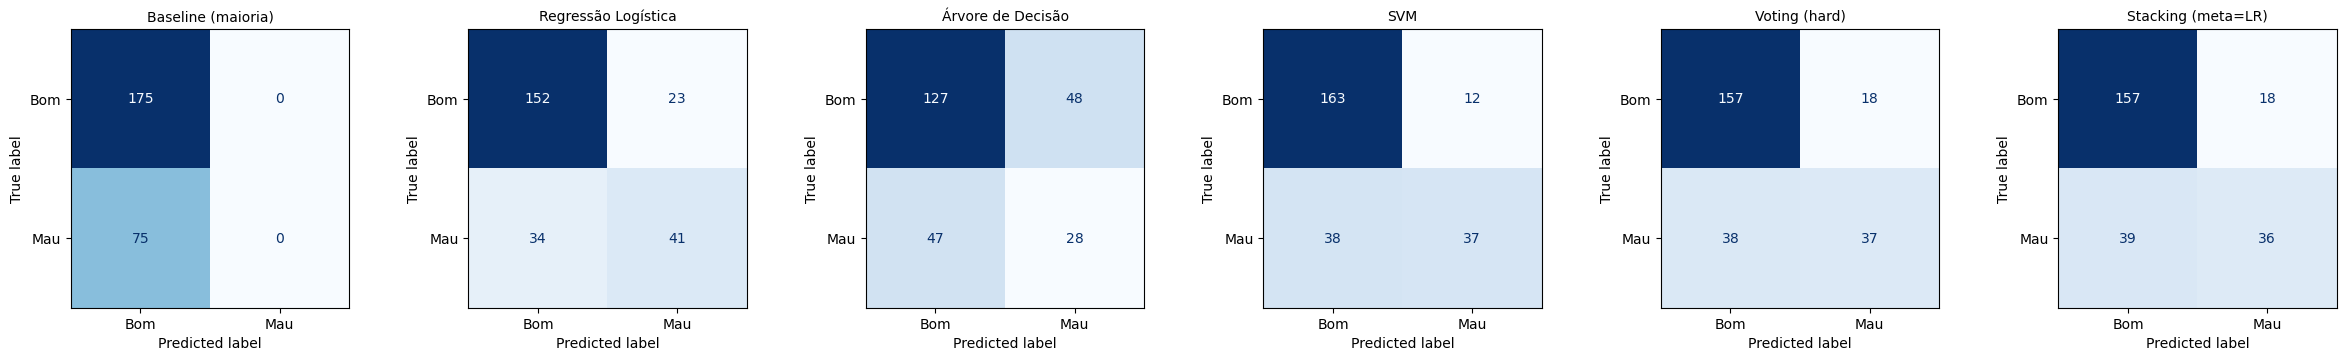

In [9]:
fig, axes = plt.subplots(1, len(modelos), figsize=(4 * len(modelos), 3.6))
for ax, (nome, m) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_te, y_te, ax=ax, colorbar=False, cmap="Blues",
        display_labels=["Bom", "Mau"])
    ax.set_title(nome, fontsize=10)
plt.tight_layout()
plt.show()

### 6.2 Validação cruzada estratificada (5 folds)
Com apenas 1000 amostras, um único split é ruidoso; a validação cruzada dá uma comparação mais estável.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1"]

linhas = []
for nome, m in modelos.items():
    r = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    linhas.append({
        "Modelo": nome,
        "Acurácia": r["test_accuracy"].mean(),
        "Precisão": r["test_precision"].mean(),
        "Recall": r["test_recall"].mean(),
        "F1": r["test_f1"].mean(),
        "F1 (desvio)": r["test_f1"].std(),
    })
cvdf = pd.DataFrame(linhas).set_index("Modelo")
cvdf

,Acurácia,Precisão,Recall,F1,F1 (desvio)
Modelo,,,,,
Baseline (maioria),0.700,0.000,0.000,0.000,0.000
Regressão Logística,0.748,0.605,0.463,0.525,0.018
Árvore de Decisão,0.707,0.518,0.360,0.420,0.062
SVM,0.760,0.684,0.373,0.482,0.038
Voting (hard),0.765,0.676,0.417,0.515,0.031
Stacking (meta=LR),0.765,0.659,0.457,0.538,0.024


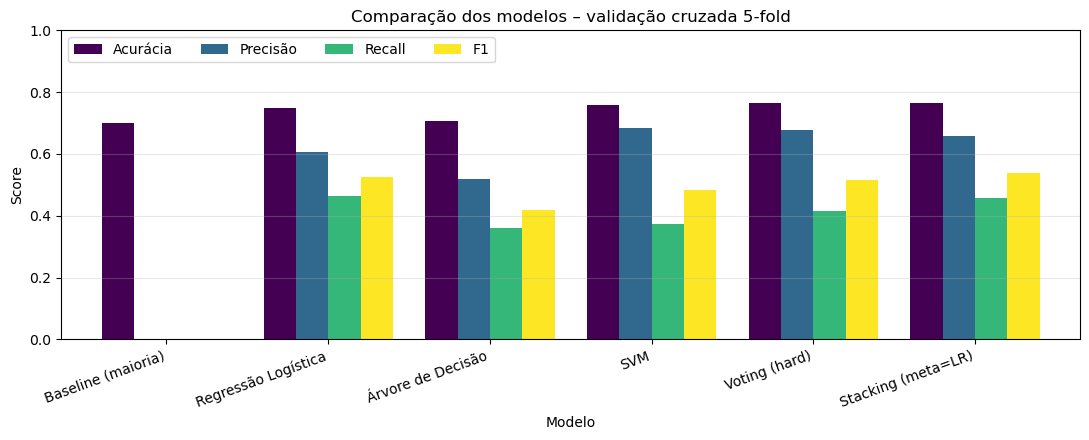

In [11]:
metricas = ["Acurácia", "Precisão", "Recall", "F1"]
ax = cvdf[metricas].plot(kind="bar", figsize=(11, 4.5), width=0.8, colormap="viridis")
ax.set_title("Comparação dos modelos – validação cruzada 5-fold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(cvdf.index, rotation=20, ha="right")
ax.legend(loc="upper left", ncol=4)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
ind = ["Regressão Logística", "Árvore de Decisão", "SVM"]
melhor_ind = cvdf.loc[ind, "F1"].idxmax()
stack_f1 = cvdf.loc["Stacking (meta=LR)", "F1"]
print(f"Melhor individual (F1 CV): {melhor_ind} = {cvdf.loc[melhor_ind, 'F1']:.3f}")
print(f"Stacking (F1 CV):          {stack_f1:.3f}")
print("Stacking superou o melhor individual?",
      "SIM" if stack_f1 > cvdf.loc[melhor_ind, "F1"] else "NÃO")
print(f"Baseline (F1 CV):          {cvdf.loc['Baseline (maioria)', 'F1']:.3f}  |  acurácia = {cvdf.loc['Baseline (maioria)', 'Acurácia']:.3f}")

Melhor individual (F1 CV): Regressão Logística = 0.525
Stacking (F1 CV):          0.538
Stacking superou o melhor individual? SIM
Baseline (F1 CV):          0.000  |  acurácia = 0.700


## 7. Discussão

### O Stacking superou os modelos individuais?
**Parcialmente.**
- **Validação cruzada:** o Stacking obteve o maior F1 (≈ 0,538 contra ≈ 0,525 da Regressão Logística) e acurácia igual à do Voting (a maior). A vantagem é pequena, menor que o desvio entre folds, portanto **não é estatisticamente conclusiva**.
- **Hold-out único:** SVM e Regressão Logística ficaram acima do Stacking, o que mostra o ruído de um split de apenas 250 amostras.

Motivos prováveis para o ganho limitado: dataset pequeno (o metamodelo treina com poucas previsões out-of-fold), modelos-base correlacionados (LR e SVM erram nos mesmos casos) e uma Árvore fraca que adiciona ruído. Em crédito, o **recall** dos maus pagadores costuma importar mais que a acurácia (falso negativo é caro). Aqui o recall é baixo em todos os modelos (cerca de 37% a 55%): na validação cruzada, a Regressão Logística tem o maior (≈ 0,463), seguida de perto pelo Stacking (≈ 0,457), que fica acima do Voting (≈ 0,417) e do SVM (≈ 0,373). No hold-out, porém, o Stacking não lidera em recall, outra evidência de que as diferenças entre os ensembles e os melhores modelos individuais são pequenas.

**Baseline:** o classificador que sempre prevê "bom pagador" atinge 70% de acurácia, com recall zero. Todos os modelos o superam em recall e F1, mas a acurácia sozinha engana: a Árvore de Decisão (0,620 no hold-out) fica *abaixo* do baseline em acurácia (e só empata com ele na validação cruzada, 0,707), o que indica sobreajuste e ruído nos ensembles que a incluem. Por isso F1 e recall são mais informativos que a acurácia neste problema.

### Em quais situações o Voting é preferível ao Stacking?
- **Poucos dados**: não há metamodelo para sobreajustar.
- **Interpretabilidade e simplicidade**: "a maioria decide" é transparente, relevante em contexto regulado como o de crédito.
- **Modelos-base de qualidade parecida**: a votação simples já aproveita a diversidade.
- **Custo e latência**: o Stacking exige validação cruzada interna (k vezes mais treinos) e uma etapa extra na inferência.

O **Stacking** é preferível quando há dados suficientes e modelos-base **diversos**, com acertos complementares: o metamodelo aprende *quanto confiar em cada um*, em vez de pesos iguais.

### Estimadores fracos homogêneos × heterogêneos
- **Homogêneos:** todos do **mesmo algoritmo**. A diversidade vem dos dados ou dos hiperparâmetros (subamostras no Bagging/Random Forest; reponderação no AdaBoost/Gradient Boosting). Ex.: 100 árvores rasas.
- **Heterogêneos:** **algoritmos diferentes**, com vieses indutivos distintos, como neste trabalho (linear, regras e kernel). É o cenário típico de Voting e Stacking.

Em ambos os casos, o ensemble só ajuda se os erros dos estimadores forem **pouco correlacionados**. Homogêneos tendem a reduzir variância (Bagging) ou viés (Boosting); heterogêneos exploram a complementaridade entre famílias de modelos.